<a href="https://colab.research.google.com/github/83devansh/StatisticsforDataScience/blob/main/practical_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("Iris.csv")

In [ ]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [ ]:
print(df.head())


   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


The output displays the first five rows of the Iris dataset. Each row contains the flower's ID, sepal length, sepal width, petal length, petal width, and species. The first five samples belong to Iris-setosa. 9.pdf

In [ ]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [ ]:
print(df.groupby('Species').mean())

                    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  \
Species                                                              
Iris-setosa       25.5          5.006         3.418          1.464   
Iris-versicolor   75.5          5.936         2.770          4.260   
Iris-virginica   125.5          6.588         2.974          5.552   

                 PetalWidthCm  
Species                        
Iris-setosa             0.244  
Iris-versicolor         1.326  
Iris-virginica          2.026  


The output displays the average measurements for each species. Iris-setosa has the smallest average petal length (1.464 cm), while Iris-virginica has the largest (5.552 cm). These differences help distinguish the species.

In [ ]:
print(df.groupby('Species').size())

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64


The output shows 50 samples for each of the three species. Therefore, the dataset is balanced, with an equal number of samples in every class.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
X = df.drop('Species', axis=1)
y = df['Species']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier


In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

In [ ]:

knn.fit(X_train, y_train)


KNeighborsClassifier()

In [ ]:
y_pred = knn.predict(X_test)

In [ ]:
print(y_pred)

['Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-setosa' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-virginica' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa']


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score


In [ ]:
cm = confusion_matrix(y_test, y_pred)

In [ ]:
print(cm)


[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


The confusion matrix shows that all 30 test samples were classified correctly:
- Iris-setosa: 10 correctly predicted.
- Iris-versicolor: 9 correctly predicted.
- Iris-virginica: 11 correctly predicted.
There are no incorrect predictions in the matrix.
Accuracy output: 100.0%
The model correctly classified all 30 test samples, resulting in an accuracy of 100% on this particular test split.

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print("Accuracy:", accuracy * 100, "%")

Accuracy: 100.0 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



The classification report shows precision, recall, F1-score, and support for each species. All three species have precision, recall, and F1-scores of 1.00, meaning the model correctly classified every test sample in this evaluation. The support values are 10, 9, and 11, respectively, for a total of 30 samples.
Conclusion: The classification report confirms the perfect performance observed in the confusion matrix for this test split.

In [ ]:
error_rate = []

for k in range(1, 26):
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    pred = knn.predict(X_test)

    error = 1 - accuracy_score(y_test, pred)

    error_rate.append(error)

print(error_rate)

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


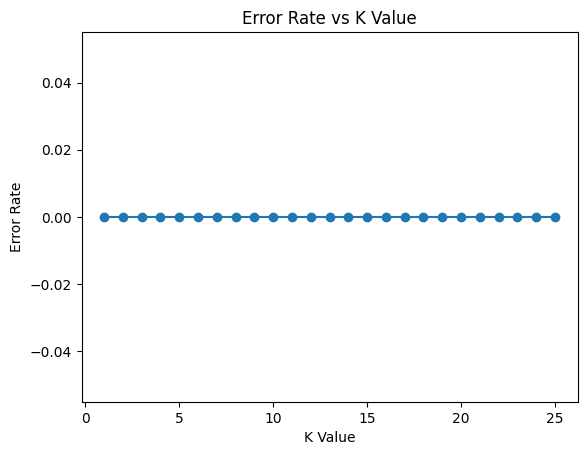

In [ ]:
import matplotlib.pyplot as plt

plt.plot(range(1, 26), error_rate, marker='o')

plt.xlabel('K Value')
plt.ylabel('Error Rate')
plt.title('Error Rate vs K Value')

plt.show()

The graph plots K values from 1 to 25 on the X-axis and error rates on the Y-axis. The line remains at zero because every tested K value produced an error rate of zero.
Conclusion: The graph indicates that all tested K values performed equally on this test split. It does not identify a uniquely best K value.

In [ ]:
best_k = error_rate.index(min(error_rate)) + 1

print("Best K:", best_k)
print("Minimum Error Rate:", min(error_rate))

Best K: 1
Minimum Error Rate: 0.0


The code selects the first K value having the minimum error rate. Because every error rate is zero, K=1 is selected simply because it appears first in the list.
Conclusion: K=1 is the first minimum-error value, but it is not uniquely better than the other tested K values. Cross-validation on the training data would provide a more reliable way to select K.

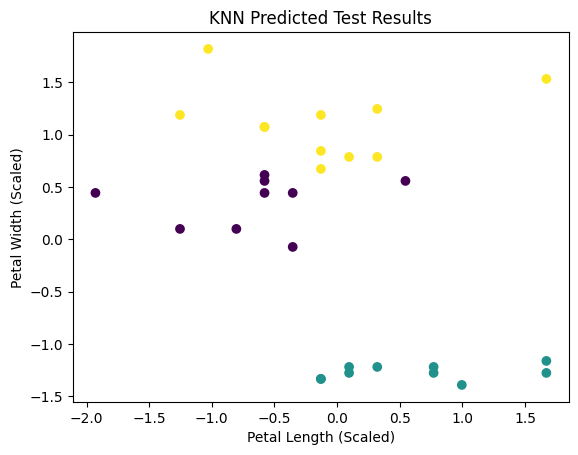

In [ ]:
plt.scatter(X_test[:, 2], X_test[:, 3],
            c=pd.factorize(y_pred)[0])

plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.title('KNN Predicted Test Results')

plt.show()

The scatter plot displays the predicted flower species for the test samples. The X-axis represents scaled petal length, and the Y-axis represents scaled petal width. Each color corresponds to a different predicted class.
The points form visually distinct groups, showing that petal measurements help separate the three Iris species.
Conclusion: The graph provides a visual representation of the KNN predictions and shows how the flower samples are distributed according to their predicted classes.